<a href="https://colab.research.google.com/github/SwastikSenSharma2/Hackkthon_AWS_AMAZON/blob/main/MSA_Endsem_3d_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/NAREN747/Generate_map.git
!find Generate_map -maxdepth 2 -type f | sort | head -100

Cloning into 'Generate_map'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 17 (delta 0), reused 17 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 37.94 KiB | 9.49 MiB/s, done.
Generate_map/ai_critic.py
Generate_map/ai_director.py
Generate_map/check_env.py
Generate_map/citygen_memory.py
Generate_map/citygen_providers.py
Generate_map/citygen.py
Generate_map/facade_texture_gen.py
Generate_map/.git/config
Generate_map/.git/description
Generate_map/.git/HEAD
Generate_map/.gitignore
Generate_map/.git/index
Generate_map/.git/packed-refs
Generate_map/LICENSE
Generate_map/osm_to_gltf.py
Generate_map/prepare_lora_dataset.py
Generate_map/quality_metrics.py
Generate_map/README.md
Generate_map/requirements.txt
Generate_map/train_facade_lora.sh


In [ ]:
%cd /content/Generate_map

print("===== README.md =====")
!cat README.md

print("\n===== requirements.txt =====")
!cat requirements.txt

print("\n===== LICENSE =====")
!cat LICENSE

/content/Generate_map
===== README.md =====
# citygen

Generate a game-ready 3D city block from real-world map data — free, local,
and runnable on a normal desktop. Built for indie developers who need a
map that isn't a stock asset pack and can't justify CityEngine or a modeling team.

Point it at a bounding box, get back a textured `.glb` with real building
footprints, real heights, optional real terrain, and AI-generated facades —
in one command.

```bash
python citygen.py --bbox 12.9716,77.5946,12.9816,77.6046 --out mycity --style downtown --terrain
```

## What it actually does

1. **Pulls real geometry from OpenStreetMap** — building footprints, heights
   (from OSM tags where available), and road networks for any bounding box
   on Earth.
2. **Extrudes it into a 3D blockout** — buildings become real 3D meshes at
   real heights, roads become correctly-widthed ribbons.
3. **(Optional) Adds real terrain** — samples elevation data and displaces
   the ground mesh, lifting buildings 

In [ ]:
!/usr/bin/python3 -m pip install --user trimesh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 751.5/751.5 kB 7.7 MB/s  0:00:00
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [ ]:
!/usr/bin/python3 -c "import trimesh; print('trimesh installed:', trimesh.__version__)"

trimesh installed: 5.2.0


In [ ]:
!pip install mapbox-earcut -r /content/Generate_map/requirements.txt

In [ ]:
%cd /content/Generate_map

!python citygen.py \
  --bbox 12.9716,77.5946,12.9816,77.6046 \
  --out /content/bengaluru_city \
  --style downtown \
  --skip-ai

/content/Generate_map

--- Fetching map data and building geometry ---
/usr/bin/python3 /content/Generate_map/osm_to_gltf.py --bbox 12.9716,77.5946,12.9816,77.6046 --out /content/bengaluru_city/city_raw.glb
Querying Overpass API...
  Overpass API query (overpass-api.de): 502 Server Error: Bad Gateway for url: https://overpass-api.de/api/interpreter, retrying in 5s (1/3)...
Parsing OSM elements...
Found 496 buildings, 755 road segments, 6545 nodes
Building 3D scene...
Buildings extruded: 496 (skipped: 0)
Roads extruded: 755
Exporting to /content/bengaluru_city/city_raw.glb ...
Done.

--- Generating facade textures ---
/usr/bin/python3 /content/Generate_map/facade_texture_gen.py --in /content/bengaluru_city/city_raw.glb --out /content/bengaluru_city/city.glb --style dense downtown commercial buildings, glass and concrete, signage --skip-ai
Total buildings textured: 0
Exported /content/bengaluru_city/city.glb

Done. Output in /content/bengaluru_city/
  /content/bengaluru_city/city.glb
  /

In [ ]:
!find /content/bengaluru_city -maxdepth 3 -type f

/content/bengaluru_city/city_raw.glb
/content/bengaluru_city/manifest.json
/content/bengaluru_city/city.glb
/content/bengaluru_city/CREDITS.txt


In [ ]:
import sys
import subprocess
import importlib
from pathlib import Path

# Create a dedicated package folder
package_dir = "/content/colab_packages"
Path(package_dir).mkdir(parents=True, exist_ok=True)

print("Python executable:", sys.executable)
print("Installing trimesh into:", package_dir)

# Install directly into this folder
result = subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--target", package_dir,
    "trimesh", "mapbox-earcut"
])

if result.returncode != 0:
    raise RuntimeError(
        "Package installation failed. Please share the complete output."
    )

# Explicitly tell Python where to find the packages
if package_dir not in sys.path:
    sys.path.insert(0, package_dir)

importlib.invalidate_caches()

# Test the imports
import trimesh
import numpy as np

print("\nSUCCESS!")
print("trimesh version:", trimesh.__version__)
print("trimesh location:", trimesh.__file__)
print("NumPy version:", np.__version__)

Python executable: /usr/bin/python3
Installing trimesh into: /content/colab_packages

SUCCESS!
trimesh version: 5.2.0
trimesh location: /content/colab_packages/trimesh/__init__.py
NumPy version: 2.1.3


In [ ]:
from pathlib import Path
import trimesh
import numpy as np

city_folder = Path("/content/bengaluru_city")
files = list(city_folder.rglob("*.glb"))

print("Number of GLB files:", len(files))

for path in files:
    print("\nFile:", path)

    scene = trimesh.load(str(path), force="scene")

    print("Number of meshes:", len(scene.geometry))
    print("Scene bounds:", np.round(scene.bounds, 2))
    print("Mesh names:", list(scene.geometry.keys())[:15])

Number of GLB files: 2

File: /content/bengaluru_city/city_raw.glb
Number of meshes: 1252
Scene bounds: [[-9.9837e+02 -9.8408e+02 -1.0000e-01]
 [ 9.2352e+02  7.4483e+02  8.0500e+01]]
Mesh names: ['geometry_0', 'geometry_1', 'geometry_2', 'geometry_3', 'geometry_4', 'geometry_5', 'geometry_6', 'geometry_7', 'geometry_8', 'geometry_9', 'geometry_10', 'geometry_11', 'geometry_12', 'geometry_13', 'geometry_14']

File: /content/bengaluru_city/city.glb
Number of meshes: 1252
Scene bounds: [[-9.9837e+02 -9.8408e+02 -1.0000e-01]
 [ 9.2352e+02  7.4483e+02  8.0500e+01]]
Mesh names: ['geometry_0', 'geometry_1', 'geometry_2', 'geometry_3', 'geometry_4', 'geometry_5', 'geometry_6', 'geometry_7', 'geometry_8', 'geometry_9', 'geometry_10', 'geometry_11', 'geometry_12', 'geometry_13', 'geometry_14']


In [ ]:
import sys
if "/content/colab_packages" not in sys.path:
    sys.path.insert(0, "/content/colab_packages")

import trimesh
import numpy as np
from pathlib import Path

city_path = Path("/content/bengaluru_city/city.glb")
scene = trimesh.load(str(city_path), force="scene")

records = []

# Apply each mesh's scene transform so its bounds are in city coordinates
for node in scene.graph.nodes_geometry:
    transform, geom_name = scene.graph.get(node)
    mesh = scene.geometry[geom_name].copy()
    mesh.apply_transform(transform)

    bounds = mesh.bounds
    extents = mesh.extents

    records.append({
        "node": str(node),
        "geometry": str(geom_name),
        "mesh": mesh,
        "x_size": float(extents[0]),
        "y_size": float(extents[1]),
        "z_size": float(extents[2]),
        "z_min": float(bounds[0, 2]),
        "z_max": float(bounds[1, 2]),
        "xy_area": float(extents[0] * extents[1]),
        "faces": len(mesh.faces)
    })

print("Total scene meshes:", len(records))
print("\nLargest horizontal-looking meshes:")

# Thin, broad surfaces are candidates for ground or road geometry.
candidates = [
    r for r in records
    if r["z_size"] < 1.0 and r["xy_area"] > 100
]
candidates.sort(key=lambda r: r["xy_area"], reverse=True)

for r in candidates[:20]:
    print(
        f'{r["geometry"]}: '
        f'X={r["x_size"]:.1f}, Y={r["y_size"]:.1f}, '
        f'Z thickness={r["z_size"]:.3f}, '
        f'z range=({r["z_min"]:.3f}, {r["z_max"]:.3f}), '
        f'faces={r["faces"]}'
    )

print("\nLargest meshes by horizontal bounding area:")
for r in sorted(records, key=lambda r: r["xy_area"], reverse=True)[:15]:
    print(
        f'{r["geometry"]}: '
        f'XY area={r["xy_area"]:.1f}, '
        f'Z range=({r["z_min"]:.2f}, {r["z_max"]:.2f}), '
        f'faces={r["faces"]}'
    )

Total scene meshes: 1252

Largest horizontal-looking meshes:
geometry_0: X=1200.0, Y=1200.0, Z thickness=0.100, z range=(-0.100, 0.000), faces=12
geometry_509: X=559.2, Y=486.6, Z thickness=0.150, z range=(0.020, 0.170), faces=252
geometry_1223: X=554.2, Y=482.4, Z thickness=0.150, z range=(0.020, 0.170), faces=1480
geometry_901: X=540.6, Y=481.5, Z thickness=0.150, z range=(0.020, 0.170), faces=432
geometry_852: X=505.7, Y=443.4, Z thickness=0.150, z range=(0.020, 0.170), faces=208
geometry_531: X=490.6, Y=349.0, Z thickness=0.150, z range=(0.020, 0.170), faces=248
geometry_551: X=374.7, Y=390.3, Z thickness=0.150, z range=(0.020, 0.170), faces=524
geometry_1151: X=548.1, Y=186.8, Z thickness=0.150, z range=(0.020, 0.170), faces=56
geometry_775: X=540.8, Y=186.0, Z thickness=0.150, z range=(0.020, 0.170), faces=60
geometry_850: X=622.0, Y=158.3, Z thickness=0.150, z range=(0.020, 0.170), faces=80
geometry_540: X=208.5, Y=459.2, Z thickness=0.150, z range=(0.020, 0.170), faces=120
geom

Ground plane: geometry_0
Ground extent: 1200.0 x 1200.0 units
Ground top elevation: 0.000
Grid dimensions: 150 x 150
Building meshes classified: 495
Open grid cells: 15570
Minute 15: maximum simulated ponding = 1.19 cm
Minute 30: maximum simulated ponding = 2.37 cm
Minute 45: maximum simulated ponding = 3.56 cm
Minute 60: maximum simulated ponding = 4.75 cm

--- Simulation results ---
Duration: 60 minutes
Maximum water depth: 4.75 cm
Mean depth over open cells: 4.75 cm
Approximate wet area: 996,480 square units


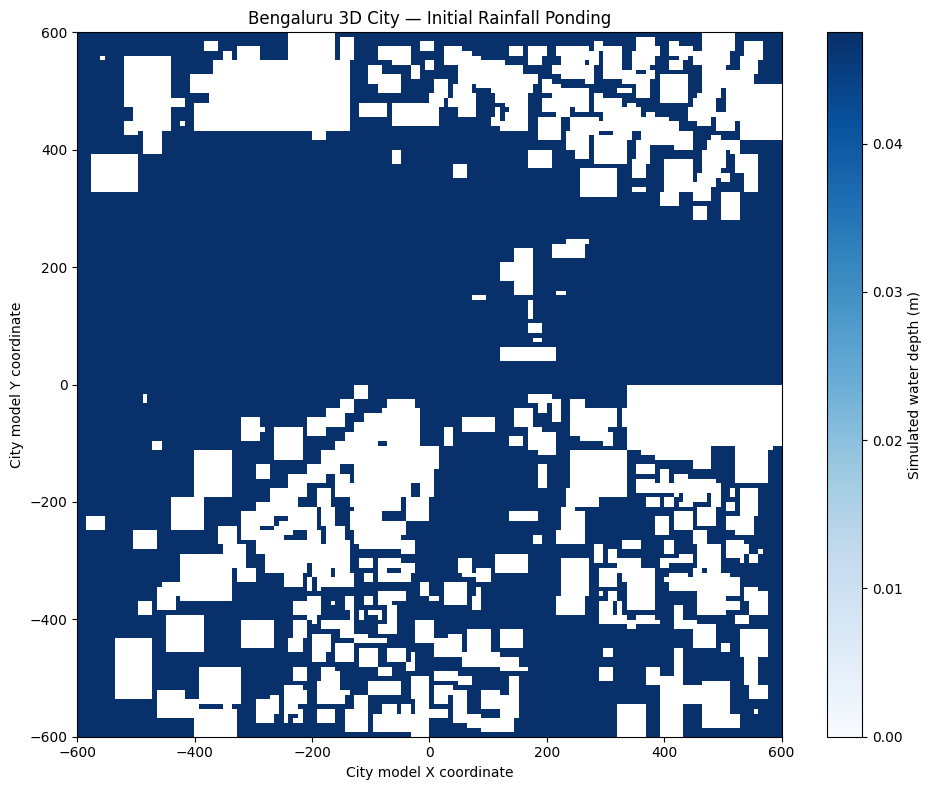

Saved depth map: /content/bengaluru_city/flood_depth.png

Flooded city saved: /content/bengaluru_city/flooded_city.glb
Flood-depth map saved: /content/bengaluru_city/flood_depth.png
Finished.


In [ ]:
# STEP 4: Simulate rainfall ponding on the generated 3D city

import sys
from pathlib import Path

if "/content/colab_packages" not in sys.path:
    sys.path.insert(0, "/content/colab_packages")

import trimesh
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load the actual 3D Bengaluru city
# --------------------------------------------------

city_path = Path("/content/bengaluru_city/city.glb")
output_dir = Path("/content/bengaluru_city")

if not city_path.exists():
    raise FileNotFoundError(f"City model not found: {city_path}")

scene = trimesh.load(str(city_path), force="scene")

# Convert scene geometry into world coordinates
records = []

for node in scene.graph.nodes_geometry:
    transform, geom_name = scene.graph.get(node)

    mesh = scene.geometry[geom_name].copy()
    mesh.apply_transform(transform)

    bounds = mesh.bounds
    extents = mesh.extents

    records.append({
        "name": str(geom_name),
        "mesh": mesh,
        "bounds": bounds,
        "z_size": float(extents[2]),
        "xy_area": float(extents[0] * extents[1])
    })

# --------------------------------------------------
# 2. Find the large flat ground plane
# --------------------------------------------------

ground_candidates = [
    r for r in records
    if r["z_size"] < 0.2 and r["xy_area"] > 500_000
]

if not ground_candidates:
    raise RuntimeError(
        "Could not identify the large flat ground plane."
    )

ground = max(ground_candidates, key=lambda r: r["xy_area"])
ground_bounds = ground["bounds"]

xmin, ymin, zmin = ground_bounds[0]
xmax, ymax, zmax = ground_bounds[1]

print("Ground plane:", ground["name"])
print(f"Ground extent: {xmax-xmin:.1f} x {ymax-ymin:.1f} units")
print(f"Ground top elevation: {zmax:.3f}")

# --------------------------------------------------
# 3. Create a 2D grid over the ground plane
# --------------------------------------------------

cell_size = 8.0  # model units; approximately 8 m if units are metres

nx = int(np.ceil((xmax - xmin) / cell_size))
ny = int(np.ceil((ymax - ymin) / cell_size))

x_edges = np.linspace(xmin, xmax, nx + 1)
y_edges = np.linspace(ymin, ymax, ny + 1)

x_centers = (x_edges[:-1] + x_edges[1:]) / 2
y_centers = (y_edges[:-1] + y_edges[1:]) / 2

dx = x_edges[1] - x_edges[0]
dy = y_edges[1] - y_edges[0]

# --------------------------------------------------
# 4. Identify approximate building footprints
# --------------------------------------------------
# Bounding boxes conservatively exclude cells around buildings.
# This is a first visualization approximation, not exact footprints.

blocked = np.zeros((ny, nx), dtype=bool)
building_records = [
    r for r in records
    if r["z_size"] > 2.0 and r["xy_area"] > 4.0
]

for record in building_records:
    b = record["bounds"]

    ix = np.where((x_centers >= b[0, 0]) &
                  (x_centers <= b[1, 0]))[0]
    iy = np.where((y_centers >= b[0, 1]) &
                  (y_centers <= b[1, 1]))[0]

    if len(ix) and len(iy):
        blocked[np.ix_(iy, ix)] = True

open_cells = ~blocked

print("Grid dimensions:", nx, "x", ny)
print("Building meshes classified:", len(building_records))
print("Open grid cells:", int(open_cells.sum()))

if not open_cells.any():
    raise RuntimeError(
        "No open cells remain. Check the building-footprint mask."
    )

# --------------------------------------------------
# 5. Run the rainfall water-balance simulation
# --------------------------------------------------

rainfall_mm_per_hour = 50.0
infiltration_mm_per_hour = 2.0
drainage_mm_per_hour = 0.5

duration_minutes = 60
time_step_seconds = 60

rain_rate = rainfall_mm_per_hour / 1000 / 3600
infiltration_rate = infiltration_mm_per_hour / 1000 / 3600
drainage_rate = drainage_mm_per_hour / 1000 / 3600

net_rate = max(
    0.0,
    rain_rate - infiltration_rate - drainage_rate
)

depth = np.zeros((ny, nx), dtype=float)

for step in range(duration_minutes * 60 // time_step_seconds):
    added_depth = net_rate * time_step_seconds
    depth[open_cells] += added_depth

    if (step + 1) % 15 == 0:
        elapsed = (step + 1) * time_step_seconds / 60
        print(
            f"Minute {elapsed:.0f}: "
            f"maximum simulated ponding = "
            f"{depth.max() * 100:.2f} cm"
        )

depth[blocked] = np.nan

wet_cells = open_cells & np.isfinite(depth) & (depth > 0)

print("\n--- Simulation results ---")
print(f"Duration: {duration_minutes} minutes")
print(f"Maximum water depth: {np.nanmax(depth) * 100:.2f} cm")
print(f"Mean depth over open cells: {np.nanmean(depth) * 100:.2f} cm")
print(f"Approximate wet area: {wet_cells.sum() * dx * dy:,.0f} square units")

# --------------------------------------------------
# 6. Save the flood-depth map
# --------------------------------------------------

depth_png = output_dir / "flood_depth.png"

plt.figure(figsize=(10, 8))
plt.imshow(
    depth,
    origin="lower",
    extent=[xmin, xmax, ymin, ymax],
    cmap="Blues",
    vmin=0,
    vmax=max(float(np.nanmax(depth)), 0.001),
    interpolation="nearest"
)
plt.colorbar(label="Simulated water depth (m)")
plt.title("Bengaluru 3D City — Initial Rainfall Ponding")
plt.xlabel("City model X coordinate")
plt.ylabel("City model Y coordinate")
plt.tight_layout()
plt.savefig(depth_png, dpi=180)
plt.show()

print("Saved depth map:", depth_png)

# --------------------------------------------------
# 7. Create a water mesh and add it to the city scene
# --------------------------------------------------

vertices = []
faces = []

# Visual exaggeration makes shallow simulated water easier to see.
# The heatmap retains the unexaggerated numerical depth.
visual_exaggeration = 3.0
water_surface_z = zmax + float(np.nanmax(depth)) * visual_exaggeration

for j, i in np.argwhere(wet_cells):
    x0, x1 = x_edges[i], x_edges[i + 1]
    y0, y1 = y_edges[j], y_edges[j + 1]

    k = len(vertices)

    vertices.extend([
        [x0, y0, water_surface_z],
        [x1, y0, water_surface_z],
        [x1, y1, water_surface_z],
        [x0, y1, water_surface_z]
    ])

    faces.extend([
        [k, k + 1, k + 2],
        [k, k + 2, k + 3]
    ])

if not faces:
    raise RuntimeError("No water-surface faces were created.")

water = trimesh.Trimesh(
    vertices=np.asarray(vertices, dtype=float),
    faces=np.asarray(faces, dtype=np.int64),
    process=False
)

water_material = trimesh.visual.material.PBRMaterial(
    name="Simulated floodwater",
    baseColorFactor=[35, 110, 255, 150],
    metallicFactor=0.0,
    roughnessFactor=0.2,
    alphaMode="BLEND",
    doubleSided=True
)

water.visual = trimesh.visual.TextureVisuals(
    material=water_material
)

scene.add_geometry(
    water,
    geom_name="Floodwater",
    node_name="Floodwater"
)

flooded_path = output_dir / "flooded_city.glb"
scene.export(str(flooded_path))

print("\nFlooded city saved:", flooded_path)
print("Flood-depth map saved:", depth_png)
print("Finished.")

In [ ]:
from google.colab import files

files.download("/content/bengaluru_city/flooded_city.glb")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("/content/bengaluru_city/flood_depth.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("/content/bengaluru_city/city.glb")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("/content/bengaluru_city/flooded_city.glb")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys
from pathlib import Path

if "/content/colab_packages" not in sys.path:
    sys.path.insert(0, "/content/colab_packages")

import trimesh
import numpy as np

# -----------------------------------------
# Load the original city
# -----------------------------------------
base_path = Path("/content/bengaluru_city/city.glb")
out_path = Path("/content/bengaluru_city/flooded_city_realistic.glb")

assert base_path.exists(), f"Missing city file: {base_path}"

scene = trimesh.load(str(base_path), force="scene")
rng = np.random.default_rng(24)

# Collect geometry in world coordinates
records = []
for node in scene.graph.nodes_geometry:
    transform, geom_name = scene.graph.get(node)
    mesh = scene.geometry[geom_name].copy()
    mesh.apply_transform(transform)

    records.append({
        "name": str(geom_name),
        "mesh": mesh,
        "bounds": mesh.bounds,
        "extent": mesh.extents
    })

# -----------------------------------------
# Find road-like, thin, ground-level meshes
# -----------------------------------------
roads = []

for r in records:
    m = r["mesh"]
    b = r["bounds"]
    e = r["extent"]

    # The generated city has thin ground-level meshes.
    # Exclude the large base plane and tall buildings.
    if (
        0.08 < e[2] < 0.30
        and b[0, 2] >= -0.02
        and b[1, 2] < 1.0
        and e[0] * e[1] > 2
    ):
        # Keep only meshes with actual upward-facing top triangles.
        top = m.face_normals[:, 2] > 0.85
        if np.any(top):
            roads.append((r, top))

print("Potential road/ground meshes:", len(roads))

if not roads:
    raise RuntimeError(
        "No suitable road surfaces detected. "
        "We need to inspect the city mesh structure."
    )

# -----------------------------------------
# Select flood zones along the roads
# -----------------------------------------
# Create clusters around road segments, not over the whole floor.
centers = np.array([
    (r["bounds"][0, :2] + r["bounds"][1, :2]) / 2
    for r, _ in roads
])

# Only use meshes with reasonably road-like dimensions.
eligible = [
    i for i, (r, _) in enumerate(roads)
    if max(r["extent"][:2]) > 12
]

if len(eligible) < 8:
    eligible = list(range(len(roads)))

seed_count = min(12, max(5, len(eligible) // 25))
seed_ids = rng.choice(eligible, size=min(seed_count, len(eligible)),
                      replace=False)
seeds = centers[seed_ids]

# Each cluster gets a different visual spread.
radii = rng.uniform(35, 85, size=len(seeds))
print("Flood zones:", len(seeds))

# -----------------------------------------
# Build water patches from road top triangles
# -----------------------------------------
water_vertices = []
water_faces = []
water_colors = []

for idx, (record, top_mask) in enumerate(roads):
    mesh = record["mesh"]
    b = record["bounds"]

    xy = (b[0, :2] + b[1, :2]) / 2
    distances = np.linalg.norm(seeds - xy, axis=1)
    zone = int(np.argmin(distances))

    # Keep only road segments close to one of our flood zones.
    if distances[zone] > radii[zone]:
        continue

    face_ids = np.where(top_mask)[0]
    if len(face_ids) == 0:
        continue

    # Water covers selected portions of roads. Irregular selection
    # creates patchy edges rather than a solid blue city floor.
    face_centers = mesh.triangles_center[face_ids]
    dist_to_seed = np.linalg.norm(
        face_centers[:, :2] - seeds[zone], axis=1
    )

    local_radius = radii[zone] * rng.uniform(0.72, 1.0)
    selected = dist_to_seed < local_radius

    # Keep a little variation at the water edge.
    selected &= rng.random(len(selected)) > (
        0.12 + 0.35 * np.clip(
            dist_to_seed / max(local_radius, 1e-6), 0, 1
        )
    )

    chosen_faces = face_ids[selected]
    if len(chosen_faces) == 0:
        continue

    # Slightly lift water above the road to avoid z-fighting.
    # Add a small spatial ripple to make the surface less uniform.
    chosen_triangles = mesh.triangles[chosen_faces].copy()
    tri_xy = chosen_triangles[:, :, :2]
    ripple = (
        0.006 * np.sin(tri_xy[:, :, 0] * 0.035)
        * np.cos(tri_xy[:, :, 1] * 0.031)
    )
    chosen_triangles[:, :, 2] += 0.035 + ripple

    # Separate triangle vertices for reliable vertex coloring.
    start = len(water_vertices)
    water_vertices.extend(chosen_triangles.reshape(-1, 3).tolist())

    face_count = len(chosen_triangles)
    for j in range(face_count):
        a = start + j * 3
        water_faces.append([a, a + 1, a + 2])

        # Darker near patch edges, brighter toward the center.
        d = np.linalg.norm(
            chosen_triangles[j, :, :2].mean(axis=0) - seeds[zone]
        )
        intensity = np.clip(d / max(radii[zone], 1), 0, 1)

        # Blue-cyan water with subtle depth variation.
        color = [
            int(20 + 18 * intensity),
            int(105 + 65 * (1 - intensity)),
            int(190 + 45 * (1 - intensity)),
            205
        ]
        water_colors.extend([color] * 3)

if not water_faces:
    raise RuntimeError(
        "No flood patches were created. "
        "Try increasing the zone radii."
    )

water = trimesh.Trimesh(
    vertices=np.asarray(water_vertices),
    faces=np.asarray(water_faces),
    process=False
)

water.visual.vertex_colors = np.asarray(water_colors, dtype=np.uint8)

scene.add_geometry(
    water,
    geom_name="Localized_Floodwater",
    node_name="Localized_Floodwater"
)

scene.export(str(out_path))

print("\nFinished!")
print("Water triangles:", len(water_faces))
print("Saved improved city:", out_path)

Potential road/ground meshes: 752
Flood zones: 12

Finished!
Water triangles: 1552
Saved improved city: /content/bengaluru_city/flooded_city_realistic.glb


In [ ]:
from google.colab import files

files.download(
    "/content/bengaluru_city/flooded_city_realistic.glb"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import sys
sys.path.insert(0, "/content/colab_packages")

import trimesh
import numpy as np
from pathlib import Path

# Paths
base = Path("/content/bengaluru_city")
input_file = base / "city.glb"
output_dir = base / "visible_flood_timeline"
output_dir.mkdir(parents=True, exist_ok=True)

# Load the original city
city = trimesh.load(input_file, force="scene")
print("Loaded city:", len(city.geometry), "meshes")

# Find the large flat ground plane
ground_z = 0.0
for name, mesh in city.geometry.items():
    if not isinstance(mesh, trimesh.Trimesh):
        continue
    ext = mesh.extents
    if ext[0] > 500 and ext[1] > 500 and ext[2] < 1:
        ground_z = float(mesh.bounds[1][2])
        print("Ground plane:", name, "height:", ground_z)
        break

# A clearly visible, opaque blue water surface.
# Increase the dimensions if you want water across more of the city.
water_width = 1050
water_depth = 1050

stages = [
    {"day": 1,  "water_z": ground_z + 0.45, "blue": [35, 145, 235, 255]},
    {"day": 7,  "water_z": ground_z + 0.75, "blue": [25, 115, 220, 255]},
    {"day": 14, "water_z": ground_z + 1.05, "blue": [15, 90, 195, 255]},
    {"day": 30, "water_z": ground_z + 1.35, "blue": [10, 65, 160, 255]},
]

for stage in stages:
    scene = city.copy()

    z = stage["water_z"]

    # Water plane sits above the ground, so it should be visible.
    water = trimesh.creation.box(
        extents=[water_width, water_depth, 0.08]
    )
    water.apply_translation([0, 0, z])
    water.visual.face_colors = stage["blue"]
    scene.add_geometry(water, geom_name=f"FLOOD_WATER_DAY_{stage['day']}")

    # Add a visible floodwater band to building-like meshes.
    # This is a visual effect, not a structural damage calculation.
    for name, mesh in list(scene.geometry.items()):
        if name.startswith("FLOOD_WATER"):
            continue
        if not isinstance(mesh, trimesh.Trimesh):
            continue

        bounds = mesh.bounds
        ext = mesh.extents

        # Select tall, reasonably sized objects; skip ground and roads.
        if ext[2] < 3 or ext[0] * ext[1] < 8:
            continue

        # Create a thin dark waterline band around the object's footprint.
        band_height = 0.22
        band_z = ground_z + 0.16
        if band_z > bounds[1][2] or band_z + band_height < bounds[0][2]:
            continue

        x0, y0 = bounds[0][:2]
        x1, y1 = bounds[1][:2]

        # Small dark-blue footprint band at the bottom of the building.
        if x1 - x0 < 0.5 or y1 - y0 < 0.5:
            continue

        band = trimesh.creation.box(
            extents=[x1-x0, y1-y0, band_height]
        )
        band.apply_translation([
            (x0+x1)/2,
            (y0+y1)/2,
            band_z + band_height/2
        ])
        band.visual.face_colors = [45, 75, 105, 255]
        scene.add_geometry(band, geom_name=f"waterline_{name}_{stage['day']}")

    output_file = output_dir / f"bengaluru_flood_day_{stage['day']:02d}.glb"
    scene.export(output_file)
    print("Saved:", output_file)

print("\nDone. Open the Day 1 and Day 30 GLB files and compare them.")


Loaded city: 1252 meshes
Ground plane: geometry_0 height: 0.0
Saved: /content/bengaluru_city/visible_flood_timeline/bengaluru_flood_day_01.glb
Saved: /content/bengaluru_city/visible_flood_timeline/bengaluru_flood_day_07.glb
Saved: /content/bengaluru_city/visible_flood_timeline/bengaluru_flood_day_14.glb
Saved: /content/bengaluru_city/visible_flood_timeline/bengaluru_flood_day_30.glb

Done. Open the Day 1 and Day 30 GLB files and compare them.


In [ ]:

from google.colab import files

files.download(
    "/content/bengaluru_city/visible_flood_timeline/bengaluru_flood_day_01.glb"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download(
    "/content/bengaluru_city/visible_flood_timeline/bengaluru_flood_day_30.glb"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
import os

CITY_DIR = Path("/content/bengaluru_city")
CITY_FILE = CITY_DIR / "city.glb"

assert CITY_FILE.exists(), (
    f"Cannot find {CITY_FILE}. Check the location of your original GLB."
)

print("Original city model:", CITY_FILE)
print("File size:", round(CITY_FILE.stat().st_size / (1024**2), 2), "MB")
print("Original file will be preserved.")


Original city model: /content/bengaluru_city/city.glb
File size: 2.03 MB
Original file will be preserved.


In [ ]:

import sys
import subprocess
from pathlib import Path

PACKAGE_DIR = "/content/colab_packages"
Path(PACKAGE_DIR).mkdir(parents=True, exist_ok=True)

sys.path.insert(0, PACKAGE_DIR)

def ensure_package(package, import_name=None):
    import_name = import_name or package.replace("-", "_")
    try:
        __import__(import_name)
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            "--quiet", "--target", PACKAGE_DIR, package
        ])
        if PACKAGE_DIR not in sys.path:
            sys.path.insert(0, PACKAGE_DIR)

        # Refresh Python's view of installed packages
        import importlib
        importlib.invalidate_caches()

ensure_package("trimesh")
ensure_package("matplotlib")
ensure_package("pillow", "PIL")

import numpy as np
import trimesh
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image

print("NumPy:", np.__version__)
print("Trimesh:", trimesh.__version__)
print("Packages ready.")


NumPy: 2.1.3
Trimesh: 5.2.0
Packages ready.


In [ ]:

scene = trimesh.load(str(CITY_FILE), force="scene")

bounds = scene.bounds
xmin, ymin, zmin = bounds[0]
xmax, ymax, zmax = bounds[1]

print("City bounds:")
print("X:", xmin, "to", xmax)
print("Y:", ymin, "to", ymax)
print("Z:", zmin, "to", zmax)
print("Meshes:", len(scene.geometry))

# Illustrative grid settings
CELL_SIZE = 12.0  # model units per cell; assumed, not verified metres

nx = int(np.ceil((xmax - xmin) / CELL_SIZE))
ny = int(np.ceil((ymax - ymin) / CELL_SIZE))

x = xmin + (np.arange(nx) + 0.5) * CELL_SIZE
y = ymin + (np.arange(ny) + 0.5) * CELL_SIZE
X, Y = np.meshgrid(x, y)

print(f"Simulation grid: {ny} rows x {nx} columns")
print(f"Total grid cells: {nx * ny:,}")


City bounds:
X: -998.370361328125 to 923.5216064453125
Y: -984.0762939453125 to 744.8313598632812
Z: -0.10000000149011612 to 80.5
Meshes: 1252
Simulation grid: 145 rows x 161 columns
Total grid cells: 23,345


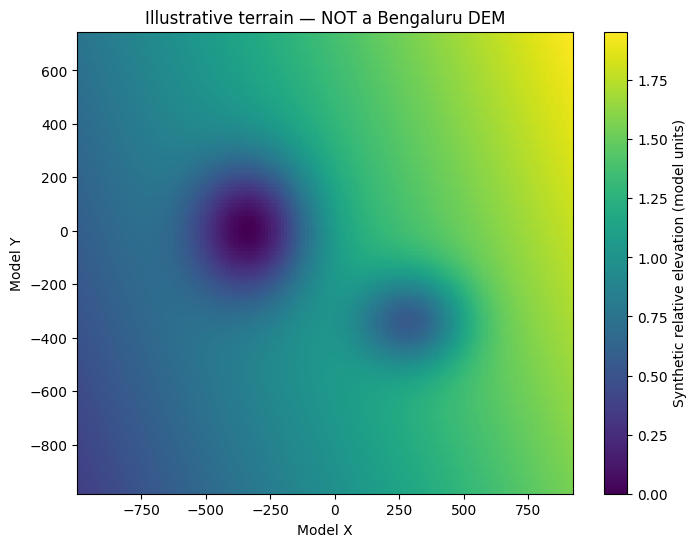

In [ ]:

# Normalize grid coordinates to approximately -1 to +1
xn = (X - X.mean()) / max((xmax - xmin) / 2, 1)
yn = (Y - Y.mean()) / max((ymax - ymin) / 2, 1)

# Assumed terrain: gentle slope + broad, synthetic depressions.
# All values are relative height offsets in model units.
terrain = (
    0.60 * xn
    + 0.20 * yn
    - 1.00 * np.exp(-(((xn + 0.30) / 0.24)**2
                      + ((yn - 0.15) / 0.30)**2))
    - 0.75 * np.exp(-(((xn - 0.35) / 0.22)**2
                      + ((yn + 0.25) / 0.20)**2))
)

# Set the minimum relative terrain height to zero
terrain -= terrain.min()

plt.figure(figsize=(8, 6))
plt.imshow(
    terrain,
    origin="lower",
    extent=[xmin, xmax, ymin, ymax],
    aspect="auto"
)
plt.colorbar(label="Synthetic relative elevation (model units)")
plt.title("Illustrative terrain — NOT a Bengaluru DEM")
plt.xlabel("Model X")
plt.ylabel("Model Y")
plt.show()


In [ ]:

# Rainfall scenario
RAINFALL_MM_PER_HOUR = 50.0
RAIN_DURATION_HOURS = 2.0
TOTAL_SIMULATION_HOURS = 4.0

# Assumed hydrological parameters
INFILTRATION_MM_PER_HOUR = 2.0
DRAINAGE_MM_PER_HOUR = 1.0

# Numerical flow parameter:
# Fraction of a surface-height difference exchanged per time step.
# This is a simplified numerical parameter, not a calibrated physical coefficient.
FLOW_COEFFICIENT = 0.08

DT_SECONDS = 60
DT_HOURS = DT_SECONDS / 3600.0

rain_depth_per_step = (
    RAINFALL_MM_PER_HOUR / 1000.0 * DT_HOURS
)
infiltration_per_step = (
    INFILTRATION_MM_PER_HOUR / 1000.0 * DT_HOURS
)
drainage_per_step = (
    DRAINAGE_MM_PER_HOUR / 1000.0 * DT_HOURS
)

n_steps = int(TOTAL_SIMULATION_HOURS * 3600 / DT_SECONDS)
rain_steps = int(RAIN_DURATION_HOURS * 3600 / DT_SECONDS)

print("Rain intensity:", RAINFALL_MM_PER_HOUR, "mm/hour")
print("Rain duration:", RAIN_DURATION_HOURS, "hours")
print("Total simulation:", TOTAL_SIMULATION_HOURS, "hours")
print("Time step:", DT_SECONDS, "seconds")
print("Number of steps:", n_steps)


Rain intensity: 50.0 mm/hour
Rain duration: 2.0 hours
Total simulation: 4.0 hours
Time step: 60 seconds
Number of steps: 240


In [ ]:

depth = np.zeros((ny, nx), dtype=np.float64)

depth_history = []
time_history = []
peak_depth_history = []
flooded_area_history = []
volume_history = []

# Each cell represents CELL_SIZE x CELL_SIZE model units.
cell_area = CELL_SIZE ** 2

def exchange_between_neighbours(depth, surface, axis):
    """Calculate one-way water transfers between neighbouring cells."""
    if axis == 1:
        h1, h2 = surface[:, :-1], surface[:, 1:]
        d1, d2 = depth[:, :-1], depth[:, 1:]
    else:
        h1, h2 = surface[:-1, :], surface[1:, :]
        d1, d2 = depth[:-1, :], depth[1:, :]

    # Positive means water moves from cell 1 to cell 2.
    difference = h1 - h2
    transfer = FLOW_COEFFICIENT * np.maximum(difference, 0.0)

    # Prevent a single edge from transferring more than the donor has.
    transfer = np.minimum(transfer, d1 * 0.20)

    # Reverse direction when cell 2 has the higher water surface.
    reverse = FLOW_COEFFICIENT * np.maximum(-difference, 0.0)
    reverse = np.minimum(reverse, d2 * 0.20)

    return transfer, reverse

for step in range(n_steps):
    t_hours = step * DT_HOURS

    # 1. Rainfall input
    if step < rain_steps:
        depth += rain_depth_per_step

    # 2. Infiltration and drainage sinks
    depth = np.maximum(depth - infiltration_per_step, 0.0)
    depth = np.maximum(depth - drainage_per_step, 0.0)

    # 3. Water flows according to total water-surface elevation
    surface = terrain + depth

    # East-west neighbour exchange
    east, west = exchange_between_neighbours(depth, surface, axis=1)

    # North-south neighbour exchange
    south, north = exchange_between_neighbours(depth, surface, axis=0)

    # Accumulate outflow and inflow for each cell
    outflow = np.zeros_like(depth)
    inflow = np.zeros_like(depth)

    outflow[:, :-1] += east
    inflow[:, 1:] += east
    outflow[:, 1:] += west
    inflow[:, :-1] += west

    outflow[:-1, :] += south
    inflow[1:, :] += south
    outflow[1:, :] += north
    inflow[:-1, :] += north

    # Scale total outflow if a cell would otherwise lose more water than it has.
    scale = np.ones_like(depth)
    mask = outflow > depth
    scale[mask] = depth[mask] / outflow[mask]

    # Apply the same scaling to transfers from each donor.
    east *= scale[:, :-1]
    west *= scale[:, 1:]
    south *= scale[:-1, :]
    north *= scale[1:, :]

    # Recompute total transfers after scaling
    outflow.fill(0)
    inflow.fill(0)

    outflow[:, :-1] += east
    inflow[:, 1:] += east
    outflow[:, 1:] += west
    inflow[:, :-1] += west
    outflow[:-1, :] += south
    inflow[1:, :] += south
    outflow[1:, :] += north
    inflow[:-1, :] += north

    depth = np.maximum(depth - outflow + inflow, 0.0)

    # Save output every 5 minutes
    if step % 5 == 0 or step == n_steps - 1:
        depth_history.append(depth.copy())
        time_history.append(t_hours + DT_HOURS)
        peak_depth_history.append(float(depth.max()))
        flooded_area_history.append(
            float(np.sum(depth > 0.01) * cell_area)
        )
        volume_history.append(float(np.sum(depth) * cell_area))

depth_history = np.asarray(depth_history)

print("Simulation complete.")
print("Saved snapshots:", len(depth_history))
print("Maximum water depth:", round(float(depth_history.max()), 4),
      "model units")


Simulation complete.
Saved snapshots: 49
Maximum water depth: 0.26 model units


In [ ]:

rain_input_per_cell = rain_depth_per_step * min(n_steps, rain_steps)
total_rain_volume = rain_input_per_cell * nx * ny * cell_area

print("Rainfall input volume (assumed m³):",
      round(total_rain_volume, 3))
print("Final surface water volume (assumed m³):",
      round(float(np.sum(depth) * cell_area), 3))
print("Final peak depth (assumed m):",
      round(float(depth.max()), 4))
print("Final flooded area above 1 cm (assumed m²):",
      round(float(np.sum(depth > 0.01) * cell_area), 2))


Rainfall input volume (assumed m³): 336168.0
Final surface water volume (assumed m³): 295827.84
Final peak depth (assumed m): 0.26
Final flooded area above 1 cm (assumed m²): 3361680.0


In [ ]:

import numpy as np

# Reconstruct the time for each saved depth snapshot.
# The solver saves a frame every 5 steps, with the final step included.
save_steps = list(range(0, n_steps, 5))

if save_steps[-1] != n_steps - 1:
    save_steps.append(n_steps - 1)

# Convert saved step numbers to elapsed simulation hours.
times = np.array([
    (step + 1) * DT_HOURS for step in save_steps
])

# Verify that the time array matches the saved depth frames.
if len(times) != len(depth_history):
    print("Time frames:", len(times))
    print("Depth frames:", len(depth_history))
    raise ValueError(
        "The arrays do not match. Please rerun the rainfall solver (Step 6), "
        "then run Step 12 again."
    )

print("Fixed! Number of time frames:", len(times))
print("First snapshot:", round(times[0], 4), "hours")
print("Last snapshot:", round(times[-1], 4), "hours")


Fixed! Number of time frames: 49
First snapshot: 0.0167 hours
Last snapshot: 4.0 hours


In [ ]:

from pathlib import Path
import numpy as np
import trimesh

# Output folder
OUT_DIR = Path("/content/bengaluru_city/rainfall_flood_simulation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Find the flat ground height from the original city model.
# Your earlier inspection found geometry_0 at z = 0.0.
ground_z = 0.0

if "geometry_0" in scene.geometry:
    ground_mesh = scene.geometry["geometry_0"]
    ground_z = float(ground_mesh.bounds[0][2])

print("Water ground reference:", ground_z)
print("Grid dimensions:", depth_history.shape[1:])

def create_water_surface(depth_grid, threshold=0.01):
    """Create a blue surface only where simulated depth exceeds threshold."""
    vertices = []
    faces = []
    colors = []

    x_edges = xmin + np.arange(nx + 1) * CELL_SIZE
    y_edges = ymin + np.arange(ny + 1) * CELL_SIZE

    for j, i in np.argwhere(depth_grid > threshold):
        x0, x1 = x_edges[i], x_edges[i + 1]
        y0, y1 = y_edges[j], y_edges[j + 1]

        # Keep water near the original flat ground.
        # Synthetic terrain influences flow, not the 3D ground elevation.
        z = ground_z + 0.08 + float(depth_grid[j, i])

        start = len(vertices)
        vertices.extend([
            [x0, y0, z],
            [x1, y0, z],
            [x1, y1, z],
            [x0, y1, z]
        ])

        faces.extend([
            [start, start + 1, start + 2],
            [start, start + 2, start + 3]
        ])

        # Deeper water becomes darker blue.
        fraction = min(float(depth_grid[j, i]) / 0.15, 1.0)
        color = [
            int(25 - 10 * fraction),
            int(125 - 45 * fraction),
            int(230 - 25 * fraction),
            255
        ]
        colors.extend([color, color])

    if not faces:
        return None

    water = trimesh.Trimesh(
        vertices=np.asarray(vertices, dtype=float),
        faces=np.asarray(faces, dtype=np.int64),
        process=False
    )
    water.visual.face_colors = np.asarray(colors, dtype=np.uint8)
    return water


# Choose the closest saved frame to each target time.
target_hours = [0.5, 1.0, 2.0, 3.0, 4.0]

for target in target_hours:
    idx = int(np.argmin(np.abs(np.asarray(times) - target)))
    depth_grid = depth_history[idx]

    water = create_water_surface(depth_grid)

    # Fresh copy each time: original scene remains unchanged.
    output_scene = scene.copy()

    if water is not None:
        output_scene.add_geometry(
            water,
            geom_name=f"FloodWater_{times[idx]:.2f}h"
        )
    else:
        print(f"No cells exceeded the water threshold at {times[idx]:.2f} h")

    filename = f"bengaluru_flood_{times[idx]:.2f}h.glb"
    output_path = OUT_DIR / filename
    output_scene.export(str(output_path))

    print(
        f"Exported: {output_path}\n"
        f"  time={times[idx]:.2f} h, "
        f"peak depth={depth_grid.max():.4f}, "
        f"wet cells={(depth_grid > 0.01).sum()}"
    )

print("\nOriginal model preserved:", CITY_FILE.exists())


Water ground reference: -0.10000000149011612
Grid dimensions: (145, 161)
Exported: /content/bengaluru_city/rainfall_flood_simulation/bengaluru_flood_0.52h.glb
  time=0.52 h, peak depth=0.0496, wet cells=23345
Exported: /content/bengaluru_city/rainfall_flood_simulation/bengaluru_flood_1.02h.glb
  time=1.02 h, peak depth=0.0979, wet cells=23345
Exported: /content/bengaluru_city/rainfall_flood_simulation/bengaluru_flood_2.02h.glb
  time=2.02 h, peak depth=0.1900, wet cells=23345
Exported: /content/bengaluru_city/rainfall_flood_simulation/bengaluru_flood_3.02h.glb
  time=3.02 h, peak depth=0.2276, wet cells=23345
Exported: /content/bengaluru_city/rainfall_flood_simulation/bengaluru_flood_4.00h.glb
  time=4.00 h, peak depth=0.2600, wet cells=23345

Original model preserved: True


In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

OUT_DIR = Path("/content/bengaluru_city/rainfall_flood_simulation")
zip_path = OUT_DIR / "bengaluru_flood_simulation_outputs.zip"

with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for path in OUT_DIR.iterdir():
        if path.is_file() and path != zip_path:
            z.write(path, arcname=path.name)

print("Files included:")
with ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        print(" -", name)

files.download(str(zip_path))


Files included:
 - bengaluru_flood_0.52h.glb
 - bengaluru_flood_4.00h.glb
 - bengaluru_flood_1.02h.glb
 - bengaluru_flood_2.02h.glb
 - bengaluru_flood_3.02h.glb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

output_dir = Path(
    "/content/bengaluru_city/rainfall_flood_simulation"
)
output_dir.mkdir(parents=True, exist_ok=True)

# List files available to package
available_files = [
    p for p in output_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".glb", ".gif", ".png", ".csv"}
]

print("Files found:", len(available_files))
for p in available_files:
    print(p.name, "-", round(p.stat().st_size / 1024, 1), "KB")

if not available_files:
    print("\nNo output files found. Run Step 13 first to export the 3D models.")
else:
    zip_path = output_dir / "bengaluru_flood_simulation_outputs.zip"

    with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
        for p in available_files:
            z.write(p, arcname=p.name)

    print("\nZIP created:", zip_path)
    print("ZIP size:", round(zip_path.stat().st_size / 1024, 1), "KB")

    # Trigger the browser download
    files.download(str(zip_path))


Files found: 5
bengaluru_flood_0.52h.glb - 4089.6 KB
bengaluru_flood_4.00h.glb - 4089.6 KB
bengaluru_flood_1.02h.glb - 4089.6 KB
bengaluru_flood_2.02h.glb - 4089.6 KB
bengaluru_flood_3.02h.glb - 4089.6 KB

ZIP created: /content/bengaluru_city/rainfall_flood_simulation/bengaluru_flood_simulation_outputs.zip
ZIP size: 5142.8 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download(
    "/content/bengaluru_city/rainfall_flood_simulation/bengaluru_flood_simulation_outputs.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>